In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
foods = pd.read_csv("../data/raw/Food_Name.csv")
nutrients = pd.read_csv("../data/raw/Nutrient_Name.csv")
amounts = pd.read_csv("../data/raw/Nutrient_Amount.csv")
food_groups = pd.read_csv("../data/raw/CNF_Food_Group.csv")

for name, df in {
    "Foods": foods,
    "Nutrients": nutrients,
    "Amounts": amounts,
    "Food Groups": food_groups
}.items():
    print(f"\n{name}: {df.shape}")
    print(df.columns.tolist())
    print(df.head(3))


Foods: (5993, 12)
['Food_Code', 'Food_Description_EN', 'Food_Description_FR', 'Alternate_Description_EN', 'Alternate_Description_FR', 'Food_Source_Code', 'USDA_NDB_Code', 'CNF_Food_Group_Code', 'Comment_EN', 'Comment_FR', 'ScientificName', 'Food_Last_Updated_Date']
   Food_Code               Food_Description_EN  \
0          2                    Cheese souffle   
1          4      Chop suey, with meat, canned   
2          5  Chinese dish, chow mein, chicken   

                Food_Description_FR Alternate_Description_EN  \
0                Soufflé au fromage                      NaN   
1  Chop suey, avec viande, conserve                      NaN   
2   Mets chinois, chow mein, poulet                      NaN   

  Alternate_Description_FR  Food_Source_Code  USDA_NDB_Code  \
0                      NaN                20            NaN   
1                 chopsuey                20            NaN   
2                      NaN                 0        36623.0   

   CNF_Food_Group_Code

In [21]:
selected = nutrients[
    nutrients["Nutrient_Name_EN"].str.contains(
        "protein|fat \\(total|carbohydrate, total|energy|fibre|fiber",
        case=False,
        na=False,
        regex=True
    )
]

print(selected[["Nutrient_Code", "Nutrient_Name_EN", "Nutrient_Unit"]].to_string(index=False))

 Nutrient_Code                    Nutrient_Name_EN Nutrient_Unit
           203                             Protein          Gram
           204                  Fat (total lipids)          Gram
           205 Carbohydrate, total (by difference)          Gram
           208               Energy (kilocalories)   kilocalorie
           268                 Energy (kilojoules)     kilojoule
           291                Fibre, total dietary          Gram


In [22]:
macro_codes = [203, 204, 205]
macro_amounts = amounts[amounts["Nutrient_Code"].isin(macro_codes)]
coverage = macro_amounts.groupby("Nutrient_Code")["Food_Code"].nunique()
print("Foods with each nutrient:")
print(coverage)
print("Missing nutrient amounts:")
print(macro_amounts["Nutrient_Amount"].isna().sum())

Foods with each nutrient:
Nutrient_Code
203    5993
204    5993
205    5993
Name: Food_Code, dtype: int64
Missing nutrient amounts:
0


In [23]:
duplicates = amounts.duplicated(subset=["Food_Code", "Nutrient_Code"]).sum()
print("Duplicate food nutrient pairs:", duplicates)

Duplicate food nutrient pairs: 0


In [24]:
nutrient_codes = {
    203: "Protein",
    204: "Fat",
    205: "Carbs",
    208: "Calories",
    291: "Fibre"
}

selected_amounts = amounts[amounts["Nutrient_Code"].isin(nutrient_codes)].copy()
print("Selected nutrient records:", selected_amounts.shape)

Selected nutrient records: (29746, 7)


In [25]:
nutrition_wide = selected_amounts.pivot(
    index="Food_Code",
    columns="Nutrient_Code",
    values="Nutrient_Amount"
)

nutrition_wide = nutrition_wide.rename(
    columns=nutrient_codes
).reset_index()

nutrition_wide.head()

Nutrient_Code,Food_Code,Protein,Fat,Carbs,Calories,Fibre
0,2,9.544150,15.704700,5.911000,204.000000,0.117000
1,4,4.074000,2.799000,5.293000,60.000000,1.149000
2,5,6.760000,2.800000,8.290000,85.000000,1.000000
3,6,8.550000,21.238000,38.623000,374.000000,1.994000
4,7,5.457754,1.909353,9.258948,76.050988,1.664603


In [26]:
food_info = foods[["Food_Code", "Food_Description_EN", "CNF_Food_Group_Code"]]
group_info = food_groups[["CNF_Food_Group_Code", "CNF_Food_Group_Description_EN"]]

nutrition_df = food_info.merge(
    nutrition_wide,
    on="Food_Code",
    how="left",
    validate="one_to_one"
)

nutrition_df = nutrition_df.merge(
    group_info,
    on="CNF_Food_Group_Code",
    how="left",
    validate="many_to_one"
)

nutrition_df.head()

,Food_Code,Food_Description_EN,CNF_Food_Group_Code,Protein,Fat,Carbs,Calories,Fibre,CNF_Food_Group_Description_EN
0,2,Cheese souffle,22,9.544150,15.704700,5.911000,204.000000,0.117000,Mixed Dishes
1,4,"Chop suey, with meat, canned",22,4.074000,2.799000,5.293000,60.000000,1.149000,Mixed Dishes
2,5,"Chinese dish, chow mein, chicken",22,6.760000,2.800000,8.290000,85.000000,1.000000,Mixed Dishes
3,6,Corn fritter,18,8.550000,21.238000,38.623000,374.000000,1.994000,Baked Products
4,7,"Frozen entree, beef pot roast with potatoes an...",22,5.457754,1.909353,9.258948,76.050988,1.664603,Mixed Dishes


In [27]:
features = ["Protein", "Fat", "Carbs", "Calories", "Fibre"]
print("Dataset shape:", nutrition_df.shape)
print("Missing values:")
print(nutrition_df[features].isna().sum())
print("Summary statistics:")
display(nutrition_df[features].describe())
print("Duplicate foods:")
print(nutrition_df["Food_Code"].duplicated().sum())
print("Negative nutritional values:")
print((nutrition_df[features] < 0).sum())
print("Foods with complete nutritional information:")
print(nutrition_df[features].notna().all(axis=1).sum())

Dataset shape: (5993, 9)
Missing values:
Protein       0
Fat           0
Carbs         0
Calories      0
Fibre       219
dtype: int64
Summary statistics:


,Protein,Fat,Carbs,Calories,Fibre
count,5993.000000,5993.000000,5993.000000,5993.000000,5774.000000
mean,10.908112,9.836596,22.815928,220.790865,2.426654
std,10.744996,16.063852,26.772984,172.082984,4.728711
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.180000,0.640000,1.100000,86.000000,0.000000
50%,7.530000,3.860000,11.100000,179.000000,0.900000
75%,18.300000,12.500000,35.670000,331.000000,2.800000
max,88.320000,100.000000,100.000000,902.000000,79.000000


Duplicate foods:
0
Negative nutritional values:
Protein     0
Fat         0
Carbs       0
Calories    0
Fibre       0
dtype: int64
Foods with complete nutritional information:
5774


In [28]:
features = ["Protein", "Fat", "Carbs", "Calories", "Fibre"]
clean_df = nutrition_df.dropna(subset=features).copy()
print("Original dataset:", nutrition_df.shape)
print("Cleaned dataset:", clean_df.shape)
print("Remaining missing values:")
print(clean_df[features].isna().sum())

Original dataset: (5993, 9)
Cleaned dataset: (5774, 9)
Remaining missing values:
Protein     0
Fat         0
Carbs       0
Calories    0
Fibre       0
dtype: int64


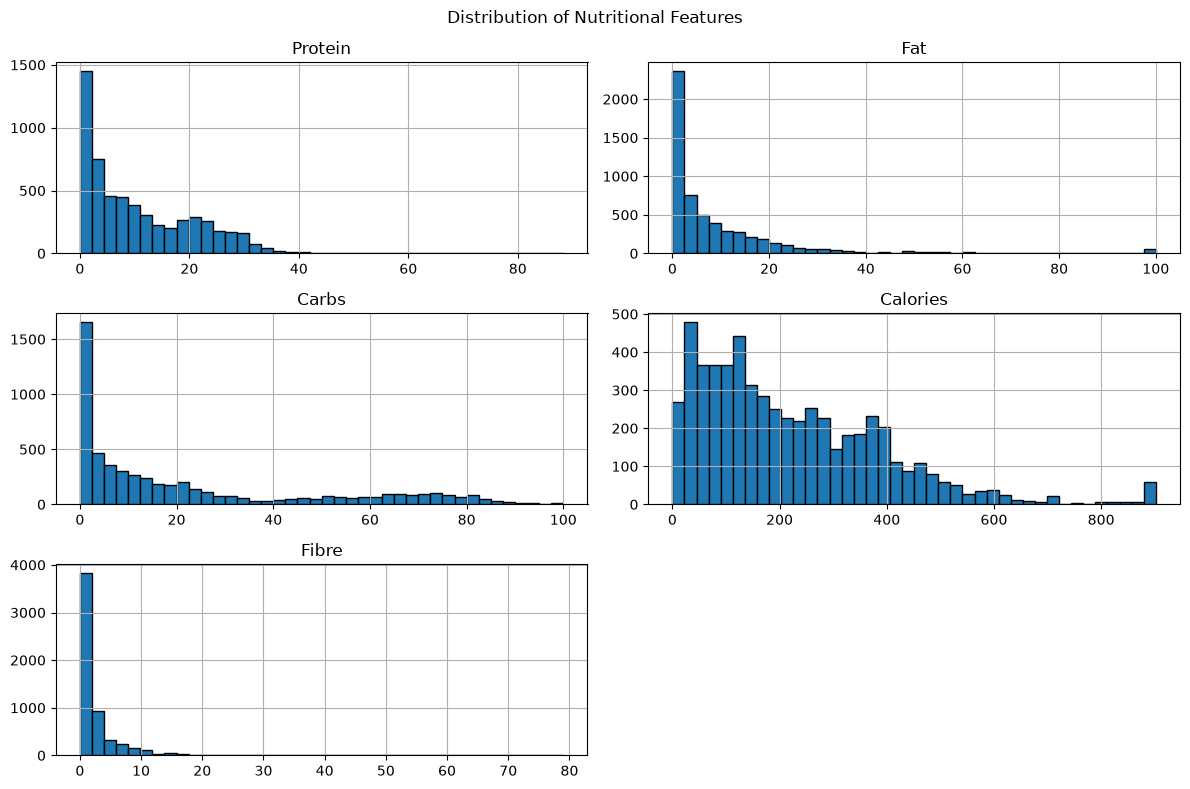

In [34]:
clean_df[features].hist(
    bins=40,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distribution of Nutritional Features")
plt.tight_layout()
plt.show()

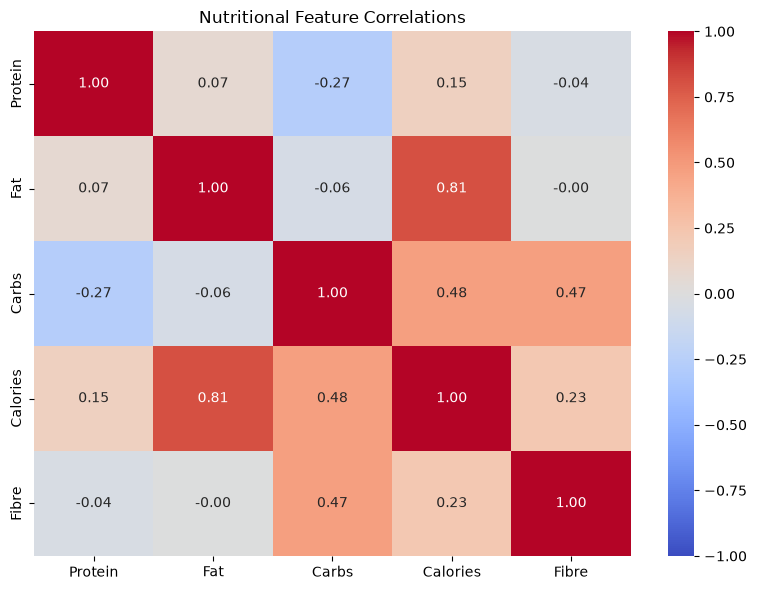

In [35]:
correlation = clean_df[features].corr()
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Nutritional Feature Correlations")
plt.tight_layout()
plt.show()

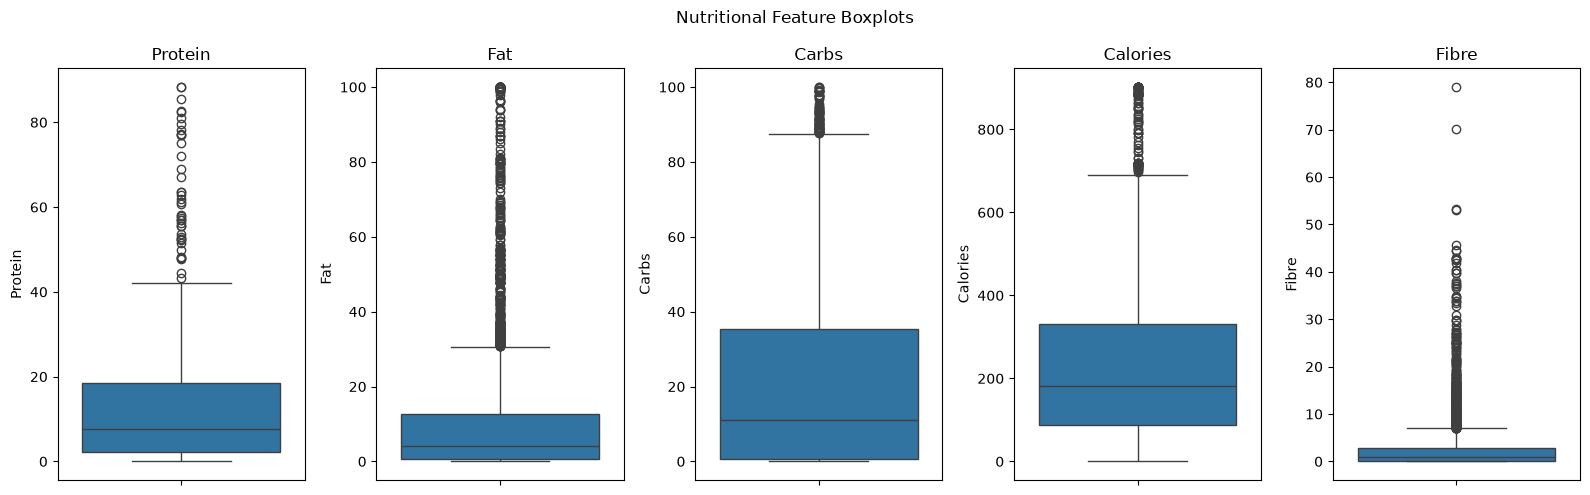

In [36]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5))

for i, feature in enumerate(features):
    sns.boxplot(
        y=clean_df[feature],
        ax=axes[i]
    )

    axes[i].set_title(feature)

plt.suptitle("Nutritional Feature Boxplots")
plt.tight_layout()
plt.show()

In [32]:
clean_df.to_csv(
    "../data/processed/foods_cleaned.csv",
    index=False
)

print("data saved.")

data saved.
